## 1. Načtení dat

Načtení červených a bílých vín z UCI Wine Quality.


In [1]:

import pandas as pd

# Nacteni datasetu Wine Quality
base_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"

red = pd.read_csv(base_url + "winequality-red.csv", sep=";")
white = pd.read_csv(base_url + "winequality-white.csv", sep=";")

# Pridani informace o typu vina
red["wine_type"] = 0
white["wine_type"] = 1

# Spojeni obou datasetu
df = pd.concat([red, white], ignore_index=True)

print("Pocet zaznamu:", len(df))
print("Pocet sloupcu:", len(df.columns))

display(df.head())


Pocet zaznamu: 6497
Pocet sloupcu: 13


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


## 2. Průzkum dat

Kontrola chybějících hodnot, rozložení kvality a duplicit.


In [2]:

# Zakladni informace o datasetu
df.info()

# Kontrola chybejicich hodnot
print("\nChybejici hodnoty:")
print(df.isnull().sum())

# Zakladni statistiky
display(df.describe())

# Rozlozeni hodnoceni kvality
print("\nPocet vin podle kvality:")
print(df["quality"].value_counts().sort_index())

# Kontrola duplicit
print("\nPocet duplicit:", df.duplicated().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB

Chybejici hodnoty:
fixed acidity           0
volatile acidity        0
cit

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378,0.753886
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255,0.430779
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000,0.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000,1.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000,1.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000,1.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000,1.000000



Pocet vin podle kvality:
quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

Pocet duplicit: 1177


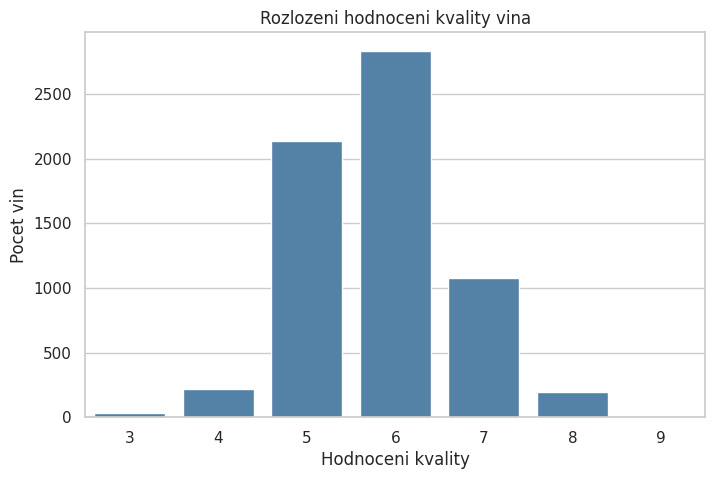

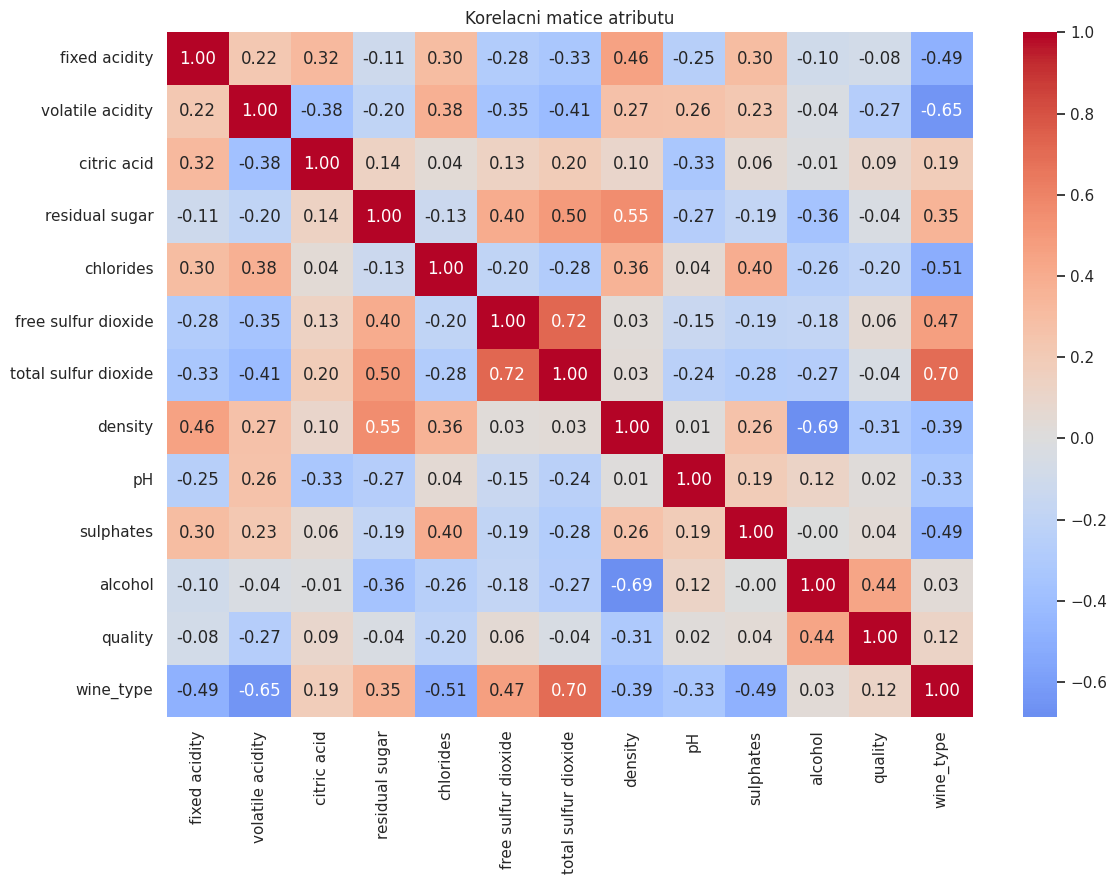

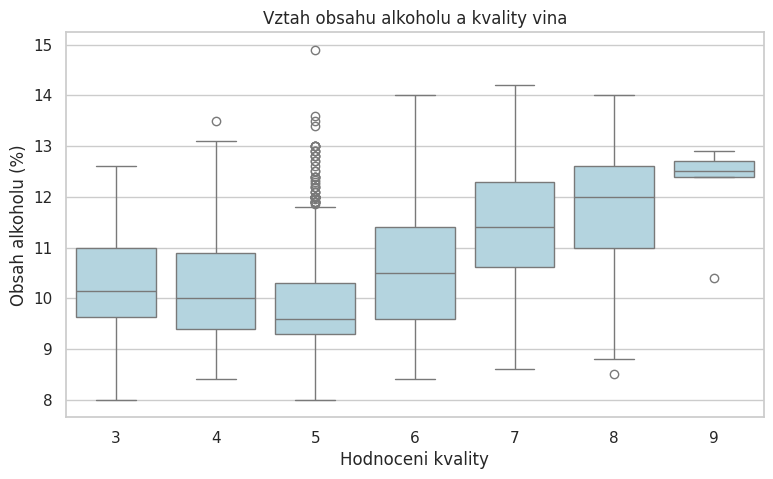

In [3]:

import matplotlib.pyplot as plt
import seaborn as sns

# Nastaveni vzhledu grafu
sns.set_theme(style="whitegrid")

# 1. Rozlozeni hodnoceni kvality vina
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality", color="steelblue")
plt.title("Rozlozeni hodnoceni kvality vina")
plt.xlabel("Hodnoceni kvality")
plt.ylabel("Pocet vin")
plt.show()

# 2. Korelacni matice
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Korelacni matice atributu")
plt.tight_layout()
plt.show()

# 3. Vztah alkoholu a kvality
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="quality", y="alcohol",
            color="lightblue")
plt.title("Vztah obsahu alkoholu a kvality vina")
plt.xlabel("Hodnoceni kvality")
plt.ylabel("Obsah alkoholu (%)")
plt.show()


## 3. Rozdělení dat

Odstranění duplicit a rozdělení na trénovací, validační a testovací množinu.


In [4]:

from sklearn.model_selection import train_test_split

# Odstraneni presnych duplicit
df_clean = df.drop_duplicates().copy()

print("Puvodni pocet zaznamu:", len(df))
print("Pocet zaznamu po odstraneni duplicit:", len(df_clean))

# Rozdeleni na vstupni atributy a cilovou hodnotu
X = df_clean.drop(columns=["quality"])
y = df_clean["quality"]

# Prvni rozdeleni: 70 % trenovani, 30 % zbytek
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Druhe rozdeleni: 15 % validace, 15 % test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("\nRozdeleni dat:")
print("Trenovaci:", len(X_train))
print("Validacni:", len(X_val))
print("Testovaci:", len(X_test))

print("\nPocet vstupnich atributu:", X_train.shape[1])

# Kontrola rozlozeni kvality v jednotlivych mnozinach
print("\nPrumerna kvalita:")
print("Trenovaci:", round(y_train.mean(), 2))
print("Validacni:", round(y_val.mean(), 2))
print("Testovaci:", round(y_test.mean(), 2))


Puvodni pocet zaznamu: 6497
Pocet zaznamu po odstraneni duplicit: 5320

Rozdeleni dat:
Trenovaci: 3724
Validacni: 798
Testovaci: 798

Pocet vstupnich atributu: 12

Prumerna kvalita:
Trenovaci: 5.8
Validacni: 5.74
Testovaci: 5.84


## 4. Standardizace

StandardScaler se učí pouze na trénovacích datech.


In [5]:

from sklearn.preprocessing import StandardScaler

# Vytvoreni normalizacniho objektu
scaler = StandardScaler()

# Normalizujeme chemicke vlastnosti
# wine_type ponechame jako 0 nebo 1
numeric_cols = X_train.columns.drop("wine_type")

# Vytvoreni kopii dat
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Vypocet prumeru a odchylek pouze na trenovacich datech
X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

# Pouziti stejne normalizace na validacni a testovaci data
X_val_scaled[numeric_cols] = scaler.transform(
    X_val[numeric_cols]
)

X_test_scaled[numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

print("Normalizace byla dokoncena.")

print("\nUkazka puvodnich dat:")
display(X_train.head())

print("\nUkazka normalizovanych dat:")
display(X_train_scaled.head())

print("\nKontrola rozmeru:")
print("Trenovaci:", X_train_scaled.shape)
print("Validacni:", X_val_scaled.shape)
print("Testovaci:", X_test_scaled.shape)


Normalizace byla dokoncena.

Ukazka puvodnich dat:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type
4683,6.6,0.17,0.35,2.6,0.030,33.0,78.0,0.99146,3.22,0.72,11.3,1
2007,6.3,0.14,0.39,1.2,0.044,26.0,116.0,0.99200,3.26,0.53,10.3,1
6097,6.8,0.20,0.25,6.2,0.052,22.0,106.0,0.99350,3.09,0.54,10.8,1
5962,7.1,0.31,0.25,11.2,0.048,32.0,136.0,0.99663,3.14,0.40,9.5,1
494,6.5,0.39,0.23,8.3,0.051,28.0,91.0,0.99520,3.44,0.55,12.1,0



Ukazka normalizovanych dat:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type
4683,-0.458445,-1.039481,0.226768,-0.549262,-0.775769,0.142201,-0.651802,-1.019137,-0.030720,1.342830,0.626548,1
2007,-0.691225,-1.218694,0.497500,-0.857809,-0.354036,-0.241993,0.013879,-0.838475,0.217301,0.006309,-0.215335,1
6097,-0.303258,-0.860268,-0.450064,0.244143,-0.113045,-0.461532,-0.161300,-0.336638,-0.836786,0.076652,0.205606,1
5962,-0.070478,-0.203154,-0.450064,1.346094,-0.233540,0.087316,0.364238,0.710529,-0.526760,-0.908153,-0.888841,1
494,-0.536039,0.274747,-0.585430,0.706962,-0.143169,-0.132223,-0.424069,0.232111,1.333393,0.146995,1.300053,0



Kontrola rozmeru:
Trenovaci: (3724, 12)
Validacni: (798, 12)
Testovaci: (798, 12)


## 5. Baseline

Jednoduchý referenční regresní model.


In [6]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Vytvoreni jednoducheho regresniho modelu
baseline = DummyRegressor(strategy="mean")

# Trenovani pouze na trenovacich datech
baseline.fit(X_train_scaled, y_train)

# Predikce na validacnich datech
y_pred_baseline = baseline.predict(X_val_scaled)

# Vypocet metrik
mae = mean_absolute_error(y_val, y_pred_baseline)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_baseline))

print("BASELINE - VYSLEDKY")
print("-------------------")
print("Predikovane hodnoceni:", round(y_pred_baseline[0], 3))
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))


BASELINE - VYSLEDKY
-------------------
Predikovane hodnoceni: 5.799
MAE: 0.7043
RMSE: 0.8899


## 6. KNN

Porovnání různých počtů sousedů.


KNN REGRESE - POROVNANI


,k,MAE,RMSE
0,3,0.5952,0.7939
1,5,0.5810,0.7623
2,7,0.5763,0.7496
3,10,0.5823,0.7502
4,15,0.5774,0.7410
5,20,0.5733,0.7375
6,30,0.5704,0.7374



Nejlepsi k: 30
Nejlepsi MAE: 0.5704
RMSE: 0.7374


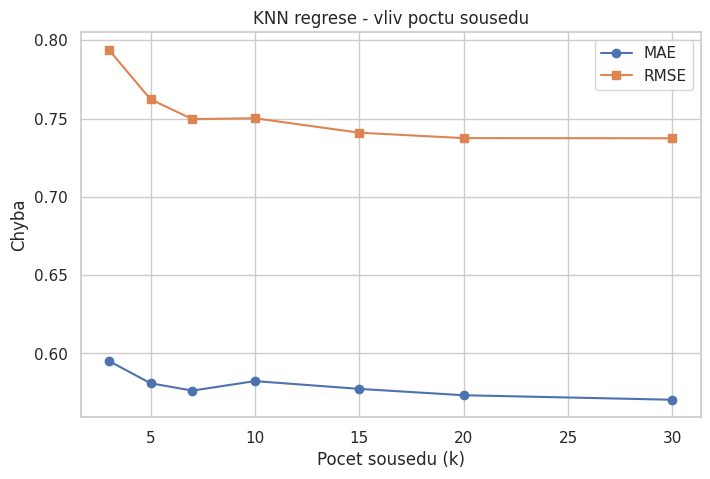

In [7]:

from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import numpy as np

# Testovane hodnoty poctu sousedu
k_values = [3, 5, 7, 10, 15, 20, 30]

results_knn = []

# Trenovani a vyhodnoceni jednotlivych modelu
for k in k_values:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_val_scaled)

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    results_knn.append({
        "k": k,
        "MAE": mae,
        "RMSE": rmse
    })

# Prehled vysledku
results_df = pd.DataFrame(results_knn)

print("KNN REGRESE - POROVNANI")
display(results_df.round(4))

# Vyber nejlepsi hodnoty k podle MAE
best_row = results_df.loc[results_df["MAE"].idxmin()]
best_k = int(best_row["k"])

print("\nNejlepsi k:", best_k)
print("Nejlepsi MAE:", round(best_row["MAE"], 4))
print("RMSE:", round(best_row["RMSE"], 4))

# Ulozeni nejlepsiho KNN modelu
knn_model = KNeighborsRegressor(n_neighbors=best_k)
knn_model.fit(X_train_scaled, y_train)

# Graf porovnani hodnot k
plt.figure(figsize=(8, 5))
plt.plot(results_df["k"], results_df["MAE"],
         marker="o", label="MAE")
plt.plot(results_df["k"], results_df["RMSE"],
         marker="s", label="RMSE")

plt.xlabel("Pocet sousedu (k)")
plt.ylabel("Chyba")
plt.title("KNN regrese - vliv poctu sousedu")
plt.legend()
plt.grid(True)
plt.show()


## 7. Vlastní model MLP v PyTorch

Model trénovaný od náhodné inicializace.


In [8]:

import torch
import torch.nn as nn
import numpy as np

# Nastaveni nahodneho seminka
torch.manual_seed(42)
np.random.seed(42)

# Prevod dat na PyTorch tensory
X_train_tensor = torch.tensor(
    X_train_scaled.to_numpy(), dtype=torch.float32
)
X_val_tensor = torch.tensor(
    X_val_scaled.to_numpy(), dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_val_tensor = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

# Definice vlastni neuronove site
class WineMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(12, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

# Vytvoreni modelu
model_mlp = WineMLP()

print("VLASTNI NEURONOVA SIT")
print("---------------------")
print(model_mlp)

print("\nRozmery trenovacich dat:")
print("X:", X_train_tensor.shape)
print("y:", y_train_tensor.shape)

print("\nPocet parametru modelu:",
      sum(p.numel() for p in model_mlp.parameters()))


VLASTNI NEURONOVA SIT
---------------------
WineMLP(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

Rozmery trenovacich dat:
X: torch.Size([3724, 12])
y: torch.Size([3724, 1])

Pocet parametru modelu: 2945


Epocha 20: Train MSE = 24.1532, Val MSE = 23.1422
Epocha 40: Train MSE = 12.8011, Val MSE = 11.9235
Epocha 60: Train MSE = 3.6549, Val MSE = 3.6305
Epocha 80: Train MSE = 2.3433, Val MSE = 2.6494
Epocha 100: Train MSE = 1.8287, Val MSE = 2.0509
Epocha 120: Train MSE = 1.6151, Val MSE = 1.8016
Epocha 140: Train MSE = 1.4845, Val MSE = 1.6615
Epocha 160: Train MSE = 1.3895, Val MSE = 1.5549
Epocha 180: Train MSE = 1.3123, Val MSE = 1.4716
Epocha 200: Train MSE = 1.2456, Val MSE = 1.4009

NEURONOVA SIT - VYSLEDKY
-----------------------
Nejlepsi epocha: 200
MAE: 0.9121
RMSE: 1.1836


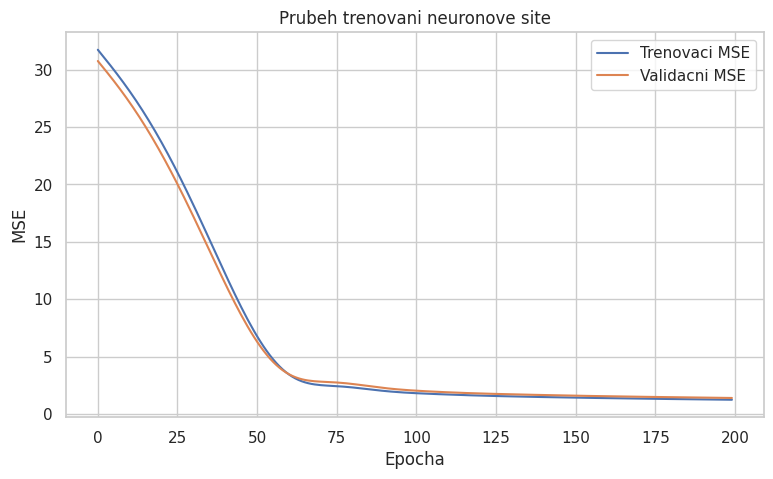

In [9]:

import copy
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Ztratova funkce a optimalizator
criterion = nn.MSELoss()
optimizer = optim.Adam(model_mlp.parameters(), lr=0.001)

# Nastaveni trenovani
epochs = 200
patience = 20

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_model_state = None
best_epoch = 0
wait = 0

# Trenovani neuronove site
for epoch in range(epochs):

    model_mlp.train()

    optimizer.zero_grad()

    train_pred = model_mlp(X_train_tensor)
    train_loss = criterion(train_pred, y_train_tensor)

    train_loss.backward()
    optimizer.step()

    # Vyhodnoceni na validacnich datech
    model_mlp.eval()

    with torch.no_grad():
        val_pred = model_mlp(X_val_tensor)
        val_loss = criterion(val_pred, y_val_tensor)

    train_losses.append(train_loss.item())
    val_losses.append(val_loss.item())

    # Ulozeni nejlepsiho modelu
    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_model_state = copy.deepcopy(model_mlp.state_dict())
        best_epoch = epoch + 1
        wait = 0
    else:
        wait += 1

    if (epoch + 1) % 20 == 0:
        print(
            f"Epocha {epoch+1}: "
            f"Train MSE = {train_loss.item():.4f}, "
            f"Val MSE = {val_loss.item():.4f}"
        )

    # Predcasne ukonceni
    if wait >= patience:
        print("\nEarly stopping v epoše:", epoch + 1)
        break

# Obnoveni nejlepsiho modelu
model_mlp.load_state_dict(best_model_state)
model_mlp.eval()

# Finalni predikce na validacnich datech
with torch.no_grad():
    y_pred_mlp = model_mlp(X_val_tensor).numpy().flatten()

mlp_mae = mean_absolute_error(y_val, y_pred_mlp)
mlp_rmse = np.sqrt(mean_squared_error(y_val, y_pred_mlp))

print("\nNEURONOVA SIT - VYSLEDKY")
print("-----------------------")
print("Nejlepsi epocha:", best_epoch)
print("MAE:", round(mlp_mae, 4))
print("RMSE:", round(mlp_rmse, 4))

# Graf prubehu trenovani
plt.figure(figsize=(9, 5))
plt.plot(train_losses, label="Trenovaci MSE")
plt.plot(val_losses, label="Validacni MSE")

plt.xlabel("Epocha")
plt.ylabel("MSE")
plt.title("Prubeh trenovani neuronove site")
plt.legend()
plt.grid(True)
plt.show()


## 8. Vylepšení MLP

Delší trénování a early stopping.


Epocha 100: Train MSE = 1.0939, Val MSE = 1.2309
Epocha 200: Train MSE = 0.7293, Val MSE = 0.8243
Epocha 300: Train MSE = 0.5933, Val MSE = 0.6734
Epocha 400: Train MSE = 0.5286, Val MSE = 0.6039
Epocha 500: Train MSE = 0.4932, Val MSE = 0.5687
Epocha 600: Train MSE = 0.4724, Val MSE = 0.5466
Epocha 700: Train MSE = 0.4584, Val MSE = 0.5326
Epocha 800: Train MSE = 0.4496, Val MSE = 0.5286
Epocha 900: Train MSE = 0.4430, Val MSE = 0.5246

Early stopping v epoše: 974

VYLEPSENA NEURONOVA SIT
----------------------
Nejlepsi epocha: 924
MAE: 0.5484
RMSE: 0.7238


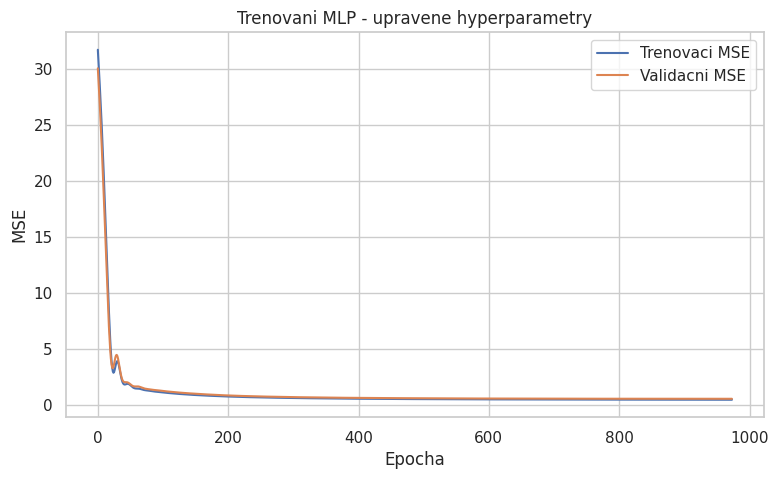

In [10]:

import copy
import torch.optim as optim
import matplotlib.pyplot as plt

# Novy model se stejnou architekturou
torch.manual_seed(42)
model_mlp_v2 = WineMLP()

criterion = nn.MSELoss()
optimizer = optim.Adam(model_mlp_v2.parameters(), lr=0.003)

epochs = 1000
patience = 50

train_losses_v2 = []
val_losses_v2 = []

best_val_loss = float("inf")
best_model_state = None
best_epoch = 0
wait = 0

for epoch in range(epochs):

    # Trenovani
    model_mlp_v2.train()
    optimizer.zero_grad()

    train_pred = model_mlp_v2(X_train_tensor)
    train_loss = criterion(train_pred, y_train_tensor)

    train_loss.backward()
    optimizer.step()

    # Validace
    model_mlp_v2.eval()

    with torch.no_grad():
        val_pred = model_mlp_v2(X_val_tensor)
        val_loss = criterion(val_pred, y_val_tensor)

    train_losses_v2.append(train_loss.item())
    val_losses_v2.append(val_loss.item())

    # Ulozeni nejlepsiho modelu
    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_model_state = copy.deepcopy(model_mlp_v2.state_dict())
        best_epoch = epoch + 1
        wait = 0
    else:
        wait += 1

    if (epoch + 1) % 100 == 0:
        print(
            f"Epocha {epoch+1}: "
            f"Train MSE = {train_loss.item():.4f}, "
            f"Val MSE = {val_loss.item():.4f}"
        )

    if wait >= patience:
        print("\nEarly stopping v epoše:", epoch + 1)
        break

# Obnoveni nejlepsiho modelu
model_mlp_v2.load_state_dict(best_model_state)
model_mlp_v2.eval()

with torch.no_grad():
    y_pred_mlp_v2 = model_mlp_v2(X_val_tensor).numpy().flatten()

mlp_v2_mae = mean_absolute_error(y_val, y_pred_mlp_v2)
mlp_v2_rmse = np.sqrt(mean_squared_error(y_val, y_pred_mlp_v2))

print("\nVYLEPSENA NEURONOVA SIT")
print("----------------------")
print("Nejlepsi epocha:", best_epoch)
print("MAE:", round(mlp_v2_mae, 4))
print("RMSE:", round(mlp_v2_rmse, 4))

# Graf
plt.figure(figsize=(9, 5))
plt.plot(train_losses_v2, label="Trenovaci MSE")
plt.plot(val_losses_v2, label="Validacni MSE")

plt.xlabel("Epocha")
plt.ylabel("MSE")
plt.title("Trenovani MLP - upravene hyperparametry")
plt.legend()
plt.grid(True)
plt.show()


POROVNANI PREDIKCI


,Skutecna kvalita,Predikovana kvalita
0,6,5.57
1,4,5.89
2,7,6.52
3,6,5.64
4,6,5.50
5,6,5.55
6,7,6.82
7,5,5.92
8,4,5.10
9,5,4.72


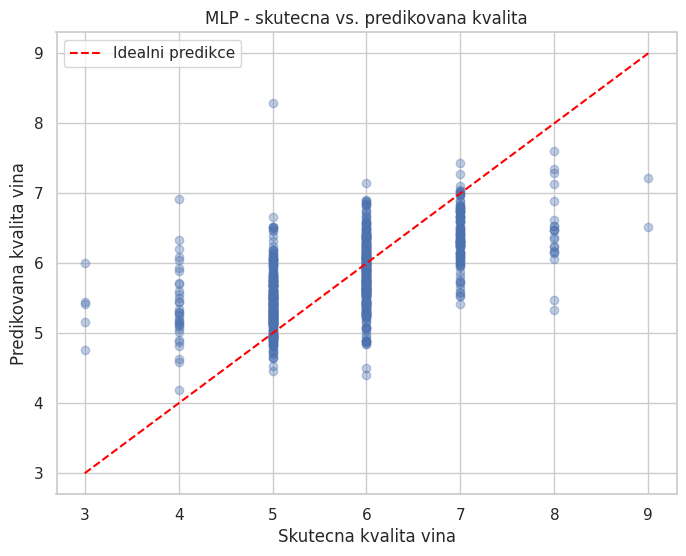


Statistika predikci:
Minimum: 4.19
Maximum: 8.28
Prumer: 5.78


In [11]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Porovnani skutecnych a predikovanych hodnot
comparison_df = pd.DataFrame({
    "Skutecna kvalita": y_val.to_numpy(),
    "Predikovana kvalita": y_pred_mlp_v2
})

print("POROVNANI PREDIKCI")
display(comparison_df.head(15).round(2))

# Graf skutecnych a predikovanych hodnot
plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    y_pred_mlp_v2,
    alpha=0.35
)

plt.plot(
    [3, 9], [3, 9],
    linestyle="--",
    color="red",
    label="Idealni predikce"
)

plt.xlabel("Skutecna kvalita vina")
plt.ylabel("Predikovana kvalita vina")
plt.title("MLP - skutecna vs. predikovana kvalita")
plt.legend()
plt.grid(True)
plt.show()

# Rozlozeni predikovanych hodnot
print("\nStatistika predikci:")
print("Minimum:", round(np.min(y_pred_mlp_v2), 2))
print("Maximum:", round(np.max(y_pred_mlp_v2), 2))
print("Prumer:", round(np.mean(y_pred_mlp_v2), 2))


## 9. Porovnávání vín

Sigmoid rozdílu předpovězených kvalit představuje skóre preference, nikoliv kalibrovanou pravděpodobnost.


POROVNANI DVOU VIN
------------------
Predikovana kvalita vina A: 5.568
Predikovana kvalita vina B: 5.886
k = 0.5: Skore preference vina A = 0.4603
k = 1: Skore preference vina A = 0.4212
k = 2: Skore preference vina A = 0.3461
k = 5: Skore preference vina A = 0.1694


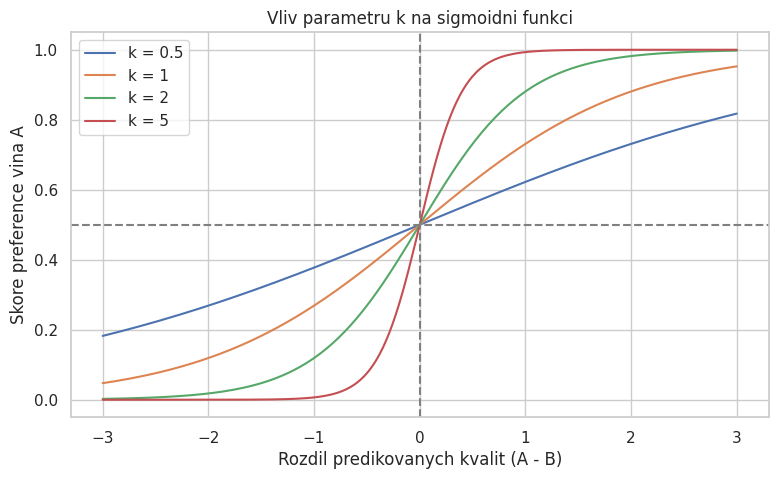

In [12]:

import numpy as np
import matplotlib.pyplot as plt

# Sigmoidni funkce
def sigmoid_difference(q_a, q_b, k=2.0):
    difference = q_a - q_b
    return 1 / (1 + np.exp(-k * difference))

# Vyber dvou vin z validacni mnoziny
wine_a = X_val_tensor[0:1]
wine_b = X_val_tensor[1:2]

# Predikce kvality obou vin
model_mlp_v2.eval()

with torch.no_grad():
    quality_a = model_mlp_v2(wine_a).item()
    quality_b = model_mlp_v2(wine_b).item()

print("POROVNANI DVOU VIN")
print("------------------")
print("Predikovana kvalita vina A:", round(quality_a, 3))
print("Predikovana kvalita vina B:", round(quality_b, 3))

# Porovnani pro ruzne hodnoty parametru k
for k in [0.5, 1, 2, 5]:
    score = sigmoid_difference(quality_a, quality_b, k)

    print(
        f"k = {k}: "
        f"Skore preference vina A = {score:.4f}"
    )

# Graf sigmoidni funkce
differences = np.linspace(-3, 3, 200)

plt.figure(figsize=(9, 5))

for k in [0.5, 1, 2, 5]:
    values = 1 / (1 + np.exp(-k * differences))
    plt.plot(differences, values, label=f"k = {k}")

plt.axhline(0.5, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")

plt.xlabel("Rozdil predikovanych kvalit (A - B)")
plt.ylabel("Skore preference vina A")
plt.title("Vliv parametru k na sigmoidni funkci")
plt.legend()
plt.grid(True)
plt.show()


In [13]:

import numpy as np
import pandas as pd

# Nahodne dvojice vin z validacni mnoziny
rng = np.random.default_rng(42)

true_quality = y_val.to_numpy()
pred_quality = y_pred_mlp_v2

n = len(true_quality)
num_pairs = 1000

pairs = []

while len(pairs) < num_pairs:
    a, b = rng.choice(n, size=2, replace=False)

    # Preskocime vina se stejnou skutecnou kvalitou
    if true_quality[a] == true_quality[b]:
        continue

    pairs.append((a, b))

# Vyhodnoceni dvojic
results = []

for a, b in pairs:
    actual_a = true_quality[a]
    actual_b = true_quality[b]

    predicted_a = pred_quality[a]
    predicted_b = pred_quality[b]

    correct = (actual_a > actual_b) == (predicted_a > predicted_b)

    results.append({
        "Skutecna A": actual_a,
        "Skutecna B": actual_b,
        "Predikce A": predicted_a,
        "Predikce B": predicted_b,
        "Spravne": correct
    })

pair_df = pd.DataFrame(results)

accuracy = pair_df["Spravne"].mean()

print("POROVNAVANI DVOU VIN")
print("--------------------")
print("Pocet dvojic:", len(pair_df))
print("Spravne porovnanych dvojic:",
      pair_df["Spravne"].sum())
print("Uspesnost:", round(accuracy * 100, 2), "%")

print("\nUkazka porovnani:")
display(pair_df.head(10).round(2))


POROVNAVANI DVOU VIN
--------------------
Pocet dvojic: 1000
Spravne porovnanych dvojic: 794
Uspesnost: 79.4 %

Ukazka porovnani:


,Skutecna A,Skutecna B,Predikce A,Predikce B,Spravne
0,6,7,5.88,7.02,True
1,6,5,6.90,5.26,True
2,6,5,5.70,5.39,True
3,6,5,5.40,5.80,False
4,5,7,5.85,6.74,True
5,6,7,5.64,6.41,True
6,6,7,5.68,6.41,True
7,8,6,6.89,4.85,True
8,5,6,5.67,5.57,False
9,5,6,5.32,5.30,False


## 10. Předtrénovaný TabPFN-2.5

Instalace a případné přihlášení. Pro běh je třeba přístup k modelu a odpovídající výpočetní prostředí.


In [14]:

# Instalace knihovny TabPFN
%pip install -q tabpfn

# Kontrola instalace
import tabpfn
from tabpfn import TabPFNRegressor

print("TabPFN je uspesne nainstalovan.")
print("Regresni model je pripraven k pouziti.")


TabPFN je uspesne nainstalovan.
Regresni model je pripraven k pouziti.


In [15]:

import os
from getpass import getpass

# Bezpecne zadani API klice
os.environ["TABPFN_TOKEN"] = getpass(
    "Vloz svuj TabPFN API klic: "
)

print("API klic byl nastaven.")


Vloz svuj TabPFN API klic: ··········
API klic byl nastaven.


## 11. Vyhodnocení TabPFN

Předtrénovaný model je přizpůsoben trénovací množině; metriky se počítají na validačních datech.


In [16]:

from tabpfn import TabPFNRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Vytvoreni predtrenovaneho regresniho modelu
model_tabpfn = TabPFNRegressor(
    model_path="tabpfn-v2.5-regressor-v2.5_default.ckpt",
    device="auto",
    random_state=42
)

print("Spoustim model TabPFN...")

# Prizpusobeni modelu trenovacim datum
model_tabpfn.fit(
    X_train.to_numpy(),
    y_train.to_numpy()
)

# Predikce na validacnich datech
y_pred_tabpfn = model_tabpfn.predict(
    X_val.to_numpy()
)

# Vypocet metrik
tabpfn_mae = mean_absolute_error(y_val, y_pred_tabpfn)
tabpfn_rmse = np.sqrt(
    mean_squared_error(y_val, y_pred_tabpfn)
)

print("\nTABPFN - VYSLEDKY")
print("----------------")
print("MAE:", round(tabpfn_mae, 4))
print("RMSE:", round(tabpfn_rmse, 4))


Spoustim model TabPFN...

TABPFN - VYSLEDKY
----------------
MAE: 0.534
RMSE: 0.6859


In [17]:

import torch

print("=== PARAMETRY MODELU TABPFN ===")

# Pokus o pristup k interni neuronove siti TabPFN
found = False

for name in ["model_", "model", "models_"]:
    internal = getattr(model_tabpfn, name, None)

    if isinstance(internal, torch.nn.Module):
        total = sum(p.numel() for p in internal.parameters())
        trainable = sum(
            p.numel() for p in internal.parameters()
            if p.requires_grad
        )

        print("Interni model:", name)
        print("Celkovy pocet parametru:", total)
        print("Parametry s requires_grad=True:", trainable)
        found = True
        break

if not found:
    print("Presny pocet parametru neni primo dostupny pres API.")
    print("TabPFN je predtrenovany model.")
    print("Pri fit() neprovadime klasicke trenovani jeho vah.")
    print("Pocet vah aktualizovanych pri fit(): 0")


=== PARAMETRY MODELU TABPFN ===
Interni model: model_
Celkovy pocet parametru: 10186760
Parametry s requires_grad=True: 10186760


### Počet parametrů modelů

Vlastní neuronová síť MLP obsahuje 9 985 parametrů, které se během trénování aktualizují. Ensemble tvořený třemi nezávisle natrénovanými sítěmi obsahuje celkem 29 955 parametrů.

Předtrénovaný model TabPFN-2.5 obsahuje 10 186 760 parametrů. Přestože mají tyto parametry nastaveno `requires_grad=True`, při použití metody `fit()` bez fine-tuningu nedochází k aktualizaci vah. Počet parametrů aktualizovaných během našeho experimentu je tedy 0.

TabPFN využívá znalosti získané během předtrénování, a proto jeho výpočetní náročnost nelze přímo porovnávat s trénováním MLP od náhodné inicializace.

POROVNANI MODELU - VALIDACNI DATA


,Model,MAE,RMSE
0,Baseline,0.7043,0.8899
1,KNN (k=30),0.5704,0.7374
2,MLP puvodni,0.9121,1.1836
3,MLP vylepsena,0.5484,0.7238
4,TabPFN-2.5,0.5340,0.6859


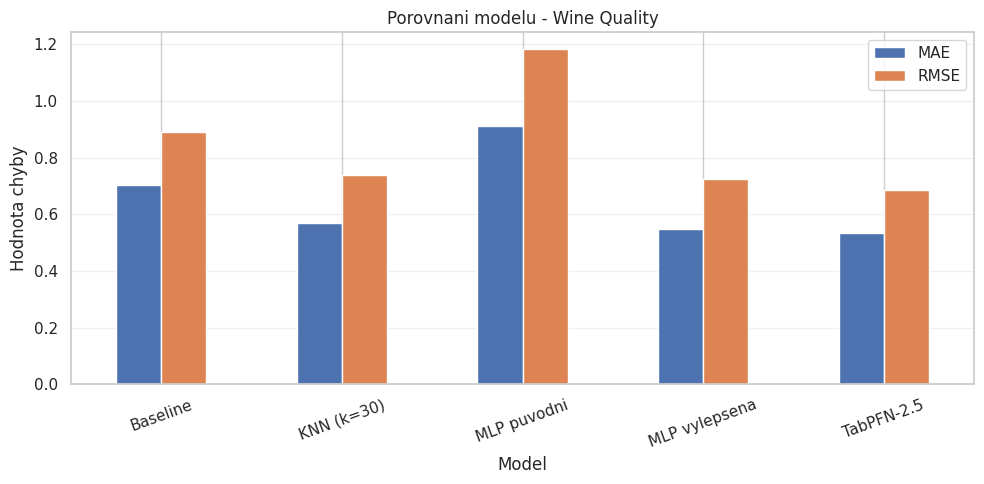

In [18]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Vypocet metrik ze skutecnych predikci
def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }

predictions = {
    "Baseline": y_pred_baseline,
    "KNN (k=30)": knn_model.predict(X_val_scaled),
    "MLP puvodni": y_pred_mlp,
    "MLP vylepsena": y_pred_mlp_v2,
    "TabPFN-2.5": y_pred_tabpfn
}

results = pd.DataFrame([
    {"Model": name, **calculate_metrics(y_val, pred)}
    for name, pred in predictions.items()
])

print("POROVNANI MODELU - VALIDACNI DATA")
display(results.round(4))

results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 5),
    rot=20
)

plt.title("Porovnani modelu - Wine Quality")
plt.ylabel("Hodnota chyby")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Hypotézy a cíle experimentů

V projektu byly navrženy následující experimenty pro ověření vlivu různých faktorů na přesnost predikce kvality vína.

### Experiment 1: Vliv learning rate

**Hypotéza:** Vhodně zvolená rychlost učení zlepší přesnost modelu MLP a umožní efektivnější trénování.

Porovnáváme learning rate 0,001; 0,003 a 0,01 při zachování stejné architektury a dat.

### Experiment 2: Vliv architektury neuronové sítě

**Hypotéza:** Větší neuronová síť dosáhne lepších výsledků než menší síť, ale může mít vyšší výpočetní náročnost.

Porovnáváme architektury 16–8, 64–32 a 128–64 neuronů při stejném learning rate.

### Experiment 3: Vliv množství trénovacích dat

**Hypotéza:** S rostoucím množstvím trénovacích dat se bude zlepšovat schopnost modelu předpovídat kvalitu vína.

Porovnáváme 25 %, 50 %, 75 % a 100 % trénovací množiny.

### Experiment 4: Kombinování více neuronových sítí

**Hypotéza:** Průměrování predikcí tří nezávisle inicializovaných modelů MLP sníží chybu oproti jednotlivým modelům.

Vyhodnocujeme ensemble tří sítí s různými náhodnými semínky.

### Hodnocení experimentů

Pro regresní úlohu používáme metriky MAE a RMSE. Nižší hodnoty znamenají přesnější predikce. Hyperparametry vybíráme na validačních datech a testovací množinu používáme až pro závěrečné vyhodnocení.

## 12. Ladění learning rate

Porovnání rychlostí učení na validační množině.


In [19]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

learning_rates = [0.001, 0.003, 0.01]
lr_results = []

# Sjednoceni rozmeru skutecnych hodnot
y_train_flat = y_train_tensor.reshape(-1)
y_val_flat = y_val_tensor.reshape(-1)

for lr in learning_rates:
    torch.manual_seed(42)

    model = WineMLP()
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience = 50
    counter = 0

    for epoch in range(1000):
        model.train()
        optimizer.zero_grad()

        predictions = model(X_train_tensor).reshape(-1)
        loss = criterion(predictions, y_train_flat)

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val_tensor).reshape(-1)
            val_loss = criterion(val_predictions, y_val_flat).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        y_pred = model(X_val_tensor).reshape(-1).cpu().numpy()

    mae = mean_absolute_error(y_val, y_pred)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))

    lr_results.append({
        "Learning rate": lr,
        "MAE": mae,
        "RMSE": rmse,
        "Nejlepsi epocha": best_epoch,
        "Celkem epoch": epoch + 1
    })

    print(f"Hotovo: learning rate = {lr}")

results_lr = pd.DataFrame(lr_results)

print("\nLADENI LEARNING RATE - OPRAVENE VYSLEDKY")
display(results_lr.round(4))


Hotovo: learning rate = 0.001
Hotovo: learning rate = 0.003
Hotovo: learning rate = 0.01

LADENI LEARNING RATE - OPRAVENE VYSLEDKY


,Learning rate,MAE,RMSE,Nejlepsi epocha,Celkem epoch
0,0.001,0.5580,0.7321,1000,1000
1,0.003,0.5484,0.7238,924,974
2,0.010,0.5453,0.7157,400,450


## 13. Porovnání architektur

Malá, střední a větší MLP.


In [20]:

import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

architectures = [
    (16, 8),
    (64, 32),
    (128, 64)
]

arch_results = []

for hidden1, hidden2 in architectures:
    torch.manual_seed(42)

    model = nn.Sequential(
        nn.Linear(X_train_tensor.shape[1], hidden1),
        nn.ReLU(),
        nn.Linear(hidden1, hidden2),
        nn.ReLU(),
        nn.Linear(hidden2, 1)
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience = 50
    counter = 0

    for epoch in range(1000):
        model.train()
        optimizer.zero_grad()

        predictions = model(X_train_tensor).reshape(-1)
        loss = criterion(predictions, y_train_tensor.reshape(-1))

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val_tensor).reshape(-1)
            val_loss = criterion(
                val_predictions,
                y_val_tensor.reshape(-1)
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        y_pred = model(X_val_tensor).reshape(-1).cpu().numpy()

    arch_results.append({
        "Architektura": f"{hidden1}-{hidden2}",
        "Pocet parametru": sum(p.numel() for p in model.parameters()),
        "MAE": mean_absolute_error(y_val, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, y_pred)),
        "Nejlepsi epocha": best_epoch
    })

    print(f"Hotovo: architektura {hidden1}-{hidden2}")

results_arch = pd.DataFrame(arch_results)

print("\nPOROVNANI ARCHITEKTUR")
display(results_arch.round(4))


Hotovo: architektura 16-8
Hotovo: architektura 64-32
Hotovo: architektura 128-64

POROVNANI ARCHITEKTUR


,Architektura,Pocet parametru,MAE,RMSE,Nejlepsi epocha
0,16-8,353,0.5575,0.7388,999
1,64-32,2945,0.5453,0.7157,400
2,128-64,9985,0.5361,0.7038,296


## 14. Stabilita modelu

Tři různá náhodná semínka pro inicializaci MLP; rozdělení dat zůstává stejné.


In [21]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

seeds = [42, 123, 2026]
seed_results = []

for seed in seeds:
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = nn.Sequential(
        nn.Linear(X_train_tensor.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience = 50
    counter = 0

    for epoch in range(1000):
        model.train()
        optimizer.zero_grad()

        predictions = model(X_train_tensor).reshape(-1)
        loss = criterion(predictions, y_train_tensor.reshape(-1))

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val_tensor).reshape(-1)
            val_loss = criterion(
                val_predictions,
                y_val_tensor.reshape(-1)
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        y_pred = model(X_val_tensor).reshape(-1).cpu().numpy()

    seed_results.append({
        "Seed": seed,
        "MAE": mean_absolute_error(y_val, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, y_pred)),
        "Nejlepsi epocha": best_epoch
    })

    print(f"Hotovo: seed = {seed}")

results_seeds = pd.DataFrame(seed_results)

print("\nVYSLEDKY PRO 3 NAHODNA SEMINKA")
display(results_seeds.round(4))

print("\nPRUMER A SMERODATNA ODCHYLKA")
print("MAE prumer:", round(results_seeds["MAE"].mean(), 4))
print("MAE smerodatna odchylka:", round(results_seeds["MAE"].std(), 4))
print("RMSE prumer:", round(results_seeds["RMSE"].mean(), 4))
print("RMSE smerodatna odchylka:", round(results_seeds["RMSE"].std(), 4))


Hotovo: seed = 42
Hotovo: seed = 123
Hotovo: seed = 2026

VYSLEDKY PRO 3 NAHODNA SEMINKA


,Seed,MAE,RMSE,Nejlepsi epocha
0,42,0.5361,0.7038,296
1,123,0.5344,0.6955,451
2,2026,0.5327,0.7011,305



PRUMER A SMERODATNA ODCHYLKA
MAE prumer: 0.5344
MAE smerodatna odchylka: 0.0017
RMSE prumer: 0.7001
RMSE smerodatna odchylka: 0.0042


## 15. Vliv množství dat

Porovnání velikostí trénovací podmnožiny při jednom náhodném výběru.


In [22]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

fractions = [0.25, 0.50, 0.75, 1.00]
data_results = []

# Stejne nahodne poradi dat pro vsechny varianty
rng = np.random.default_rng(42)
indices = rng.permutation(len(X_train_tensor))

for fraction in fractions:
    n_samples = int(len(indices) * fraction)
    selected_indices = indices[:n_samples]

    X_subset = X_train_tensor[selected_indices]
    y_subset = y_train_tensor[selected_indices].reshape(-1)

    torch.manual_seed(42)

    model = nn.Sequential(
        nn.Linear(X_train_tensor.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience = 50
    counter = 0

    for epoch in range(1000):
        model.train()
        optimizer.zero_grad()

        predictions = model(X_subset).reshape(-1)
        loss = criterion(predictions, y_subset)

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val_tensor).reshape(-1)
            val_loss = criterion(
                val_predictions,
                y_val_tensor.reshape(-1)
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        y_pred = model(X_val_tensor).reshape(-1).cpu().numpy()

    data_results.append({
        "Podil dat": f"{int(fraction * 100)} %",
        "Pocet vzorku": n_samples,
        "MAE": mean_absolute_error(y_val, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, y_pred)),
        "Nejlepsi epocha": best_epoch
    })

    print(f"Hotovo: {int(fraction * 100)} % dat")

results_data = pd.DataFrame(data_results)

print("\nVLIV MNOZSTVI TRENOVACICH DAT")
display(results_data.round(4))


Hotovo: 25 % dat
Hotovo: 50 % dat
Hotovo: 75 % dat
Hotovo: 100 % dat

VLIV MNOZSTVI TRENOVACICH DAT


,Podil dat,Pocet vzorku,MAE,RMSE,Nejlepsi epocha
0,25 %,931,0.5528,0.7298,300
1,50 %,1862,0.5360,0.7089,290
2,75 %,2793,0.5356,0.7036,269
3,100 %,3724,0.5363,0.7039,295


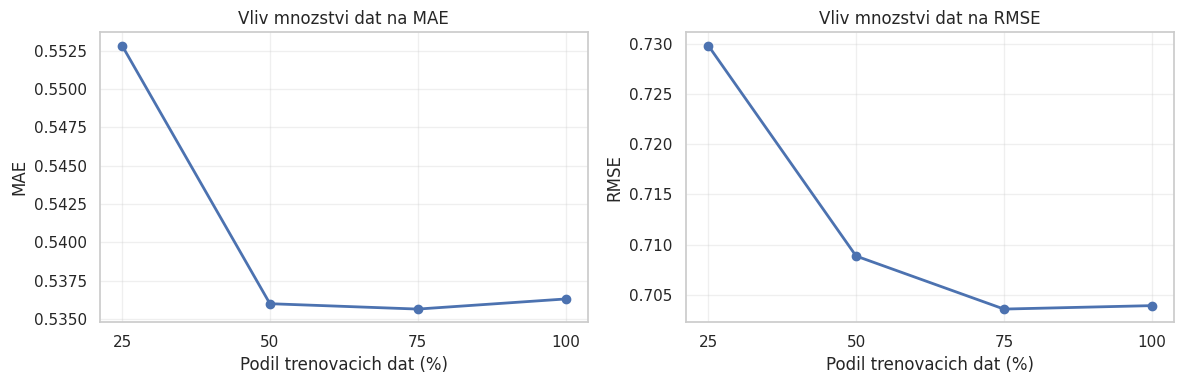

Graf byl ulozen jako experiment_mnozstvi_dat.png


In [23]:

import matplotlib.pyplot as plt

percentages = [25, 50, 75, 100]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    percentages,
    results_data["MAE"],
    marker="o",
    linewidth=2
)
axes[0].set_title("Vliv mnozstvi dat na MAE")
axes[0].set_xlabel("Podil trenovacich dat (%)")
axes[0].set_ylabel("MAE")
axes[0].set_xticks(percentages)
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    percentages,
    results_data["RMSE"],
    marker="o",
    linewidth=2
)
axes[1].set_title("Vliv mnozstvi dat na RMSE")
axes[1].set_xlabel("Podil trenovacich dat (%)")
axes[1].set_ylabel("RMSE")
axes[1].set_xticks(percentages)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("experiment_mnozstvi_dat.png", dpi=300)
plt.show()

print("Graf byl ulozen jako experiment_mnozstvi_dat.png")


## 16. Ensemble MLP

Průměr predikcí tří samostatně trénovaných sítí.


In [24]:

import torch
import torch.nn as nn
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

seeds = [42, 123, 2026]
all_predictions = []

for seed in seeds:
    torch.manual_seed(seed)

    model = nn.Sequential(
        nn.Linear(X_train_tensor.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    patience = 50
    counter = 0

    for epoch in range(1000):
        model.train()
        optimizer.zero_grad()

        predictions = model(X_train_tensor).reshape(-1)
        loss = criterion(
            predictions,
            y_train_tensor.reshape(-1)
        )

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val_tensor).reshape(-1)
            val_loss = criterion(
                val_predictions,
                y_val_tensor.reshape(-1)
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        y_pred = model(X_val_tensor).reshape(-1).cpu().numpy()

    all_predictions.append(y_pred)
    print(f"Hotovo: seed = {seed}")

# Prumer predpovedi tri modelu
y_pred_ensemble = np.mean(all_predictions, axis=0)

ensemble_mae = mean_absolute_error(y_val, y_pred_ensemble)
ensemble_rmse = np.sqrt(mean_squared_error(y_val, y_pred_ensemble))

print("\nENSEMBLE TRI NEURONOVYCH SITI")
print(f"MAE: {ensemble_mae:.4f}")
print(f"RMSE: {ensemble_rmse:.4f}")


Hotovo: seed = 42
Hotovo: seed = 123
Hotovo: seed = 2026

ENSEMBLE TRI NEURONOVYCH SITI
MAE: 0.5300
RMSE: 0.6930


## 17. Porovnávání dvojic na validaci

Vyhodnocení náhodných dvojic; dvojice nejsou nezávislá pozorování.


In [25]:

import numpy as np
import pandas as pd
from scipy.special import expit

# Sigmoid funkce pro porovnani dvou vin
def wine_preference(quality_a, quality_b, k=2):
    return expit(k * (quality_a - quality_b))

# Nahodny vyber 1000 dvojic z validacnich dat
rng = np.random.default_rng(42)

real_quality = np.asarray(y_val).reshape(-1)
pred_quality = np.asarray(y_pred_ensemble).reshape(-1)

n_pairs = 1000
pairs = []

for _ in range(n_pairs):
    a, b = rng.choice(len(real_quality), size=2, replace=False)

    real_a = real_quality[a]
    real_b = real_quality[b]

    pred_a = pred_quality[a]
    pred_b = pred_quality[b]

    score = wine_preference(pred_a, pred_b, k=2)

    # Dvojice se stejnou skutecnou kvalitou nehodnotime
    if real_a == real_b:
        continue

    predicted_better_a = pred_a > pred_b
    actual_better_a = real_a > real_b

    pairs.append({
        "Skutecna kvalita A": real_a,
        "Skutecna kvalita B": real_b,
        "Predikce A": pred_a,
        "Predikce B": pred_b,
        "Preference A": score,
        "Spravne": predicted_better_a == actual_better_a
    })

pair_results = pd.DataFrame(pairs)

accuracy = pair_results["Spravne"].mean() * 100

print("POROVNANI DVOJIC VIN")
print(f"Vygenerovano dvojic: {n_pairs}")
print(f"Hodnoceno dvojic: {len(pair_results)}")
print(f"Spravne porovnani: {pair_results['Spravne'].sum()}")
print(f"Presnost: {accuracy:.2f} %")

print("\nUKAZKA PRVNICH 10 DVOJIC")
display(pair_results.head(10).round(3))


POROVNANI DVOJIC VIN
Vygenerovano dvojic: 1000
Hodnoceno dvojic: 668
Spravne porovnani: 547
Presnost: 81.89 %

UKAZKA PRVNICH 10 DVOJIC


,Skutecna kvalita A,Skutecna kvalita B,Predikce A,Predikce B,Preference A,Spravne
0,6,7,6.260,6.772,0.264,True
1,6,5,6.833,5.366,0.949,True
2,6,5,5.777,5.263,0.736,True
3,6,5,5.470,5.592,0.439,False
4,5,7,5.724,6.583,0.152,True
5,6,7,5.648,6.467,0.163,True
6,6,7,5.869,6.467,0.232,True
7,8,6,6.767,4.917,0.976,True
8,5,6,5.459,5.501,0.479,True
9,5,6,5.104,5.238,0.434,True


## 18. Závěrečné testování

Testovací data nejsou použita pro výběr hyperparametrů.


In [26]:

import torch
import torch.nn as nn
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Priprava testovacich dat
X_test_tensor = torch.tensor(
    np.asarray(X_test_scaled),
    dtype=torch.float32
)

# Tri modely se stejnym nastavenim jako drive
seeds = [42, 123, 2026]
test_predictions = []

for seed in seeds:
    torch.manual_seed(seed)

    model = nn.Sequential(
        nn.Linear(X_train_tensor.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    patience = 50
    counter = 0

    for epoch in range(1000):
        model.train()
        optimizer.zero_grad()

        predictions = model(X_train_tensor).reshape(-1)
        loss = criterion(
            predictions,
            y_train_tensor.reshape(-1)
        )

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val_tensor).reshape(-1)
            val_loss = criterion(
                val_predictions,
                y_val_tensor.reshape(-1)
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        pred = model(X_test_tensor).reshape(-1).cpu().numpy()

    test_predictions.append(pred)
    print(f"Hotovo: seed = {seed}")

# Prumer predpovedi
y_pred_test_ensemble = np.mean(test_predictions, axis=0)

test_mae_ensemble = mean_absolute_error(
    y_test, y_pred_test_ensemble
)

test_rmse_ensemble = np.sqrt(
    mean_squared_error(y_test, y_pred_test_ensemble)
)

print("\nTESTOVACI VYSLEDKY - ENSEMBLE MLP")
print(f"MAE: {test_mae_ensemble:.4f}")
print(f"RMSE: {test_rmse_ensemble:.4f}")


Hotovo: seed = 42
Hotovo: seed = 123
Hotovo: seed = 2026

TESTOVACI VYSLEDKY - ENSEMBLE MLP
MAE: 0.5247
RMSE: 0.6599


### Uložení finálních modelů a konfigurace

In [27]:

import torch
import os

# Slozka pro ulozeni modelu
os.makedirs("ulozene_modely", exist_ok=True)

# Ulozime kazdy ze tri modelu MLP
# Vahy znovu natrenujeme se stejnym nastavenim jako ve finalnim testu

seeds = [42, 123, 2026]

for seed in seeds:
    torch.manual_seed(seed)

    model = torch.nn.Sequential(
        torch.nn.Linear(X_train_tensor.shape[1], 128),
        torch.nn.ReLU(),
        torch.nn.Linear(128, 64),
        torch.nn.ReLU(),
        torch.nn.Linear(64, 1)
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = torch.nn.MSELoss()

    best_val_loss = float("inf")
    best_state = None
    patience = 50
    counter = 0

    for epoch in range(1000):
        model.train()
        optimizer.zero_grad()

        predictions = model(X_train_tensor).reshape(-1)
        loss = criterion(predictions, y_train_tensor.reshape(-1))

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val_tensor).reshape(-1)
            val_loss = criterion(
                val_predictions,
                y_val_tensor.reshape(-1)
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                key: value.detach().clone()
                for key, value in model.state_dict().items()
            }
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            break

    model.load_state_dict(best_state)

    cesta = f"ulozene_modely/mlp_seed_{seed}.pth"
    torch.save(model.state_dict(), cesta)

    print(f"Ulozen model: {cesta}")

print("\nVsechny tri modely byly uspesne ulozeny.")


Ulozen model: ulozene_modely/mlp_seed_42.pth
Ulozen model: ulozene_modely/mlp_seed_123.pth
Ulozen model: ulozene_modely/mlp_seed_2026.pth

Vsechny tri modely byly uspesne ulozeny.


In [28]:

import os
import json
import joblib

# Slozka uz obsahuje ulozene vahy tri MLP
os.makedirs("ulozene_modely", exist_ok=True)

# Ulozeni scaleru natrenovaneho pouze na trenovacich datech
joblib.dump(scaler, "ulozene_modely/scaler.joblib")

# Konfigurace finalniho MLP a poradi atributu
config = {
    "model": "MLP",
    "input_size": int(X_train_tensor.shape[1]),
    "hidden_layers": [128, 64],
    "output_size": 1,
    "activation": "ReLU",
    "optimizer": "Adam",
    "learning_rate": 0.01,
    "loss": "MSE",
    "max_epochs": 1000,
    "early_stopping_patience": 50,
    "seeds": [42, 123, 2026],
    "input_features": X_train.columns.tolist(),
    "scaled_features": list(numeric_cols),
    "unscaled_features": ["wine_type"]
}

with open("ulozene_modely/config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=4, ensure_ascii=False)

print("Scaler a konfigurace byly ulozeny.")
print("\nObsah slozky ulozene_modely:")
for filename in sorted(os.listdir("ulozene_modely")):
    print("-", filename)


Scaler a konfigurace byly ulozeny.

Obsah slozky ulozene_modely:
- config.json
- mlp_seed_123.pth
- mlp_seed_2026.pth
- mlp_seed_42.pth
- scaler.joblib


### Výpočetní náročnost a rychlost inference

In [29]:

import time
import pandas as pd
from tabpfn import TabPFNRegressor

# Mereni casu prizpusobeni TabPFN
times_tabpfn = []

for seed in [42, 123, 2026]:
    model = TabPFNRegressor(
        model_path="tabpfn-v2.5-regressor-v2.5_default.ckpt",
        device="auto",
        random_state=seed
    )

    start = time.perf_counter()

    model.fit(
        X_train.to_numpy(),
        y_train.to_numpy()
    )

    elapsed = time.perf_counter() - start

    times_tabpfn.append({
        "Seed": seed,
        "Cas fit (s)": elapsed
    })

results_tabpfn_time = pd.DataFrame(times_tabpfn)

print("=== CAS PRIZPUSOBENI TABPFN ===")
display(results_tabpfn_time.round(4))

print(
    "\nPrumerny cas fit:",
    round(results_tabpfn_time["Cas fit (s)"].mean(), 4),
    "sekund"
)

results_tabpfn_time.to_csv(
    "cas_prizpusobeni_tabpfn.csv",
    index=False
)


=== CAS PRIZPUSOBENI TABPFN ===


,Seed,Cas fit (s)
0,42,0.3582
1,123,0.3194
2,2026,0.2977



Prumerny cas fit: 0.3251 sekund


In [30]:

import time
import platform
import numpy as np
import pandas as pd
import torch

print("=== POUZITY HARDWARE ===")
print("Procesor:", platform.processor() or "Nezjisten")
print("PyTorch:", torch.__version__)
print("CUDA dostupna:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Priprava testovacich dat
X_test_np = X_test.to_numpy()
X_test_scaled_np = X_test_scaled

# Nacteni ulozenych modelu MLP
models_mlp = []

for seed in [42, 123, 2026]:
    model = torch.nn.Sequential(
        torch.nn.Linear(X_train_tensor.shape[1], 128),
        torch.nn.ReLU(),
        torch.nn.Linear(128, 64),
        torch.nn.ReLU(),
        torch.nn.Linear(64, 1)
    )

    model.load_state_dict(
        torch.load(
            f"ulozene_modely/mlp_seed_{seed}.pth",
            map_location="cpu",
            weights_only=True
        )
    )

    model.eval()
    models_mlp.append(model)

# Pocet parametru jednoho MLP
params_mlp = sum(
    p.numel() for p in models_mlp[0].parameters()
)

print("\nParametry jednoho MLP:", params_mlp)
print("Parametry celeho ensemble:", params_mlp * 3)

# Funkce pro mereni inference
def measure_inference(predict_fn, repetitions=20):
    times = []

    # Zahrev
    for _ in range(3):
        predict_fn()

    for _ in range(repetitions):
        start = time.perf_counter()
        predict_fn()
        elapsed = time.perf_counter() - start
        times.append(elapsed)

    return np.mean(times) * 1000, np.std(times) * 1000

def predict_ensemble():
    with torch.no_grad():
        predictions = [
            model(X_test_tensor.cpu()).numpy().reshape(-1)
            for model in models_mlp
        ]
    return np.mean(predictions, axis=0)

measurements = []

for name, function in [
    ("Baseline", lambda: baseline.predict(X_test_scaled_np)),
    ("KNN", lambda: knn_model.predict(X_test_scaled_np)),
    ("MLP ensemble", predict_ensemble),
    ("TabPFN-2.5", lambda: model_tabpfn.predict(X_test_np))
]:
    mean_ms, std_ms = measure_inference(function)

    measurements.append({
        "Model": name,
        "Prumerny cas (ms)": mean_ms,
        "Smerodatna odchylka (ms)": std_ms,
        "Pocet vzorku": len(X_test)
    })

results_inference = pd.DataFrame(measurements)

print("\n=== RYCHLOST INFERENCE ===")
display(results_inference.round(3))

results_inference.to_csv(
    "rychlost_inference.csv",
    index=False
)


=== POUZITY HARDWARE ===
Procesor: x86_64
PyTorch: 2.11.0+cu130
CUDA dostupna: True
GPU: Tesla T4

Parametry jednoho MLP: 9985
Parametry celeho ensemble: 29955

=== RYCHLOST INFERENCE ===


,Model,Prumerny cas (ms),Smerodatna odchylka (ms),Pocet vzorku
0,Baseline,0.037,0.012,798
1,KNN,49.458,3.513,798
2,MLP ensemble,1.094,0.063,798
3,TabPFN-2.5,3062.874,101.325,798


In [31]:

import time
import torch
import torch.nn as nn
import pandas as pd

# Mereni casu trenovani MLP
seeds = [42, 123, 2026]
training_times = []

for seed in seeds:
    torch.manual_seed(seed)

    # Stejna architektura jako u finalniho MLP
    model = nn.Sequential(
        nn.Linear(X_train_tensor.shape[1], 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 1)
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()

    best_val_loss = float("inf")
    best_epoch = 0
    patience = 50
    counter = 0

    # Zacatek mereni casu
    start = time.perf_counter()

    for epoch in range(1000):
        model.train()
        optimizer.zero_grad()

        predictions = model(X_train_tensor).reshape(-1)
        loss = criterion(
            predictions,
            y_train_tensor.reshape(-1)
        )

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val_tensor).reshape(-1)
            val_loss = criterion(
                val_predictions,
                y_val_tensor.reshape(-1)
            ).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1
            counter = 0
        else:
            counter += 1

        if counter >= patience:
            break

    elapsed = time.perf_counter() - start

    training_times.append({
        "Seed": seed,
        "Cas trenovani (s)": elapsed,
        "Nejlepsi epocha": best_epoch,
        "Celkem epoch": epoch + 1
    })

    print(f"Hotovo: seed {seed}, cas {elapsed:.2f} s")

results_training_time = pd.DataFrame(training_times)

print("\n=== CAS TRENOVANI MLP ===")
display(results_training_time.round(3))

print(
    "\nPrumerny cas jednoho MLP:",
    round(results_training_time["Cas trenovani (s)"].mean(), 3),
    "sekund"
)

print(
    "Celkovy cas tri MLP:",
    round(results_training_time["Cas trenovani (s)"].sum(), 3),
    "sekund"
)

results_training_time.to_csv(
    "cas_trenovani_mlp.csv",
    index=False
)


Hotovo: seed 42, cas 1.77 s
Hotovo: seed 123, cas 2.57 s
Hotovo: seed 2026, cas 2.21 s

=== CAS TRENOVANI MLP ===


,Seed,Cas trenovani (s),Nejlepsi epocha,Celkem epoch
0,42,1.770,296,346
1,123,2.570,451,501
2,2026,2.213,305,355



Prumerny cas jednoho MLP: 2.184 sekund
Celkovy cas tri MLP: 6.552 sekund


### Analýza chyb a reziduí

=== PRUMERNA ABSOLUTNI CHYBA PODLE KVALITY ===


MLP ensemble       TabPFN-2.5      
                         mean count       mean count
Skutecna kvalita                                    
3                       3.050     1      2.886     1
4                       1.211    33      1.233    33
5                       0.471   249      0.526   249
6                       0.389   343      0.358   343
7                       0.645   156      0.599   156
8                       1.523    16      1.497    16

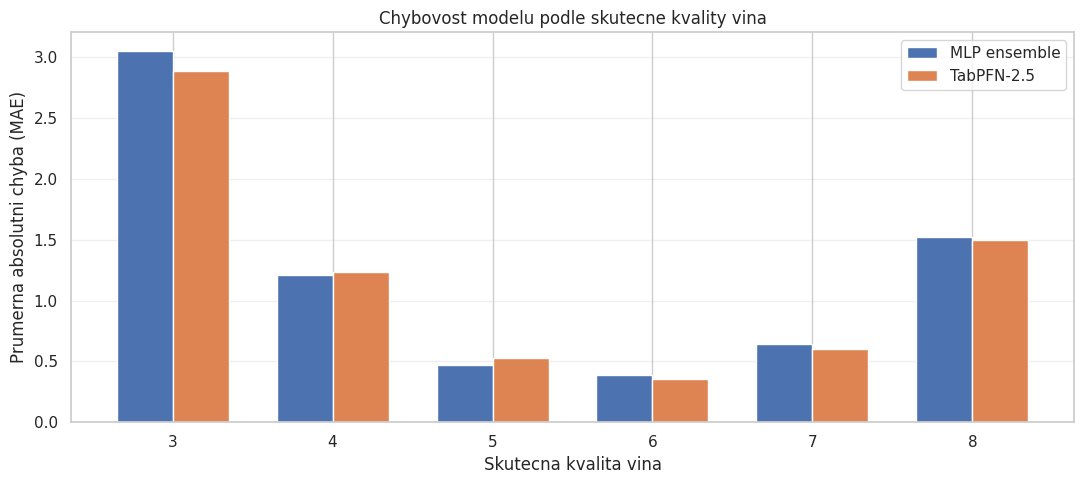


Graf byl ulozen.


In [32]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Skutecne hodnoty kvality na testovacich datech
y_true = np.asarray(y_test).reshape(-1)


# Predikce na TESTOVACICH datech
predictions = {
    "MLP ensemble": np.asarray(y_pred_test_ensemble).reshape(-1),
    "TabPFN-2.5": np.asarray(
        model_tabpfn.predict(X_test.to_numpy())
    ).reshape(-1)
}


# Vypocet absolutni chyby pro kazde vino
error_data = pd.DataFrame({
    "Skutecna kvalita": y_true
})

for model_name, y_pred in predictions.items():
    error_data[model_name] = np.abs(y_true - y_pred)

# Prumerna absolutni chyba podle skutecne kvality
errors_by_quality = error_data.groupby(
    "Skutecna kvalita"
).agg(["mean", "count"])

print("=== PRUMERNA ABSOLUTNI CHYBA PODLE KVALITY ===")
display(errors_by_quality.round(3))

# Graf
quality_values = sorted(np.unique(y_true))
x = np.arange(len(quality_values))
width = 0.35

plt.figure(figsize=(11, 5))

for i, model_name in enumerate(predictions.keys()):
    means = [
        error_data.loc[
            error_data["Skutecna kvalita"] == q,
            model_name
        ].mean()
        for q in quality_values
    ]

    plt.bar(
        x + (i - 0.5) * width,
        means,
        width,
        label=model_name
    )

plt.xticks(x, quality_values)
plt.xlabel("Skutecna kvalita vina")
plt.ylabel("Prumerna absolutni chyba (MAE)")
plt.title("Chybovost modelu podle skutecne kvality vina")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("analyza_chyb_podle_kvality.png", dpi=300)
plt.show()

print("\nGraf byl ulozen.")


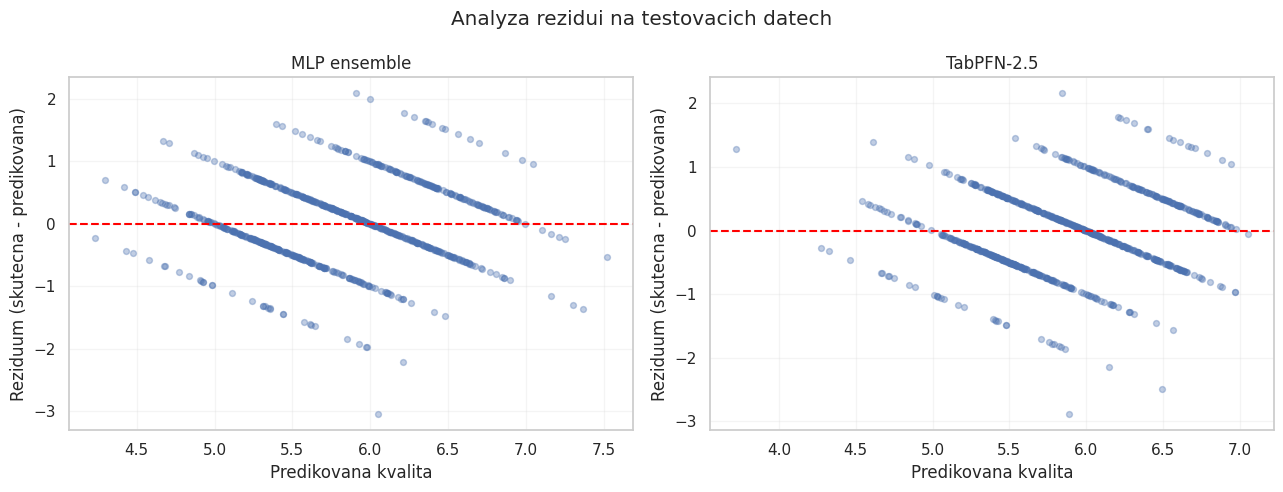

=== SHRNUTI REZIDUI ===

MLP ensemble
Prumerne reziduum: 0.0166
Smerodatna odchylka: 0.6597
Nejvetsi absolutni chyba: 3.0502

TabPFN-2.5
Prumerne reziduum: -0.0301
Smerodatna odchylka: 0.6469
Nejvetsi absolutni chyba: 2.8860


In [33]:

import numpy as np
import matplotlib.pyplot as plt

# Reziduum = skutecna hodnota - predikovana hodnota
y_true = np.asarray(y_test).reshape(-1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    residuals = y_true - y_pred

    ax.scatter(
        y_pred,
        residuals,
        alpha=0.35,
        s=18
    )

    ax.axhline(0, color="red", linestyle="--")

    ax.set_title(model_name)
    ax.set_xlabel("Predikovana kvalita")
    ax.set_ylabel("Reziduum (skutecna - predikovana)")
    ax.grid(alpha=0.2)

plt.suptitle("Analyza rezidui na testovacich datech")
plt.tight_layout()
plt.savefig("analyza_rezidui.png", dpi=300)
plt.show()

print("=== SHRNUTI REZIDUI ===")

for model_name, y_pred in predictions.items():
    residuals = y_true - y_pred

    print(f"\n{model_name}")
    print(f"Prumerne reziduum: {np.mean(residuals):.4f}")
    print(f"Smerodatna odchylka: {np.std(residuals):.4f}")
    print(f"Nejvetsi absolutni chyba: {np.max(np.abs(residuals)):.4f}")


### Trénovací křivky finálního MLP

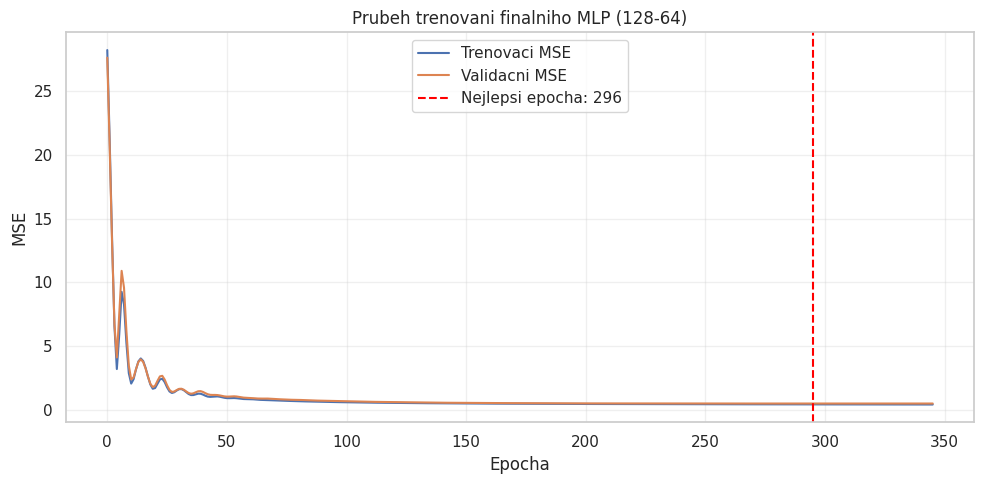

Nejlepsi epocha: 296
Nejlepsi validacni MSE: 0.4953
Celkem epoch: 346


In [34]:

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import copy

torch.manual_seed(42)

model_curve = nn.Sequential(
    nn.Linear(X_train_tensor.shape[1], 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 1)
)

optimizer = torch.optim.Adam(model_curve.parameters(), lr=0.01)
criterion = nn.MSELoss()

train_losses = []
val_losses = []

best_val = float("inf")
best_epoch = 0
best_state = None
patience = 50
counter = 0

for epoch in range(1000):
    model_curve.train()
    optimizer.zero_grad()

    train_pred = model_curve(X_train_tensor).reshape(-1)
    train_loss = criterion(train_pred, y_train_tensor.reshape(-1))
    train_loss.backward()
    optimizer.step()

    model_curve.eval()
    with torch.no_grad():
        train_mse = criterion(
            model_curve(X_train_tensor).reshape(-1),
            y_train_tensor.reshape(-1)
        ).item()

        val_mse = criterion(
            model_curve(X_val_tensor).reshape(-1),
            y_val_tensor.reshape(-1)
        ).item()

    train_losses.append(train_mse)
    val_losses.append(val_mse)

    if val_mse < best_val:
        best_val = val_mse
        best_epoch = epoch + 1
        best_state = copy.deepcopy(model_curve.state_dict())
        counter = 0
    else:
        counter += 1

    if counter >= patience:
        break

model_curve.load_state_dict(best_state)

plt.figure(figsize=(10, 5))
plt.plot(train_losses, label="Trenovaci MSE")
plt.plot(val_losses, label="Validacni MSE")
plt.axvline(
    best_epoch - 1,
    color="red",
    linestyle="--",
    label=f"Nejlepsi epocha: {best_epoch}"
)

plt.xlabel("Epocha")
plt.ylabel("MSE")
plt.title("Prubeh trenovani finalniho MLP (128-64)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("finalni_mlp_krivky.png", dpi=300)
plt.show()

print("Nejlepsi epocha:", best_epoch)
print("Nejlepsi validacni MSE:", round(best_val, 4))
print("Celkem epoch:", len(train_losses))


### Statistické porovnání MLP a TabPFN

In [35]:

import pandas as pd

# Statisticke vyhodnoceni tri behu MLP
print("=== VYSLEDKY TRI BEHU MLP ===")
display(results_seeds.round(4))

statistics = pd.DataFrame({
    "Metrika": ["MAE", "RMSE"],
    "Prumer": [
        results_seeds["MAE"].mean(),
        results_seeds["RMSE"].mean()
    ],
    "Smerodatna odchylka": [
        results_seeds["MAE"].std(ddof=1),
        results_seeds["RMSE"].std(ddof=1)
    ],
    "Pocet behu": [3, 3]
})

print("\n=== STATISTICKE SHRNUTI ===")
display(statistics.round(4))

for _, row in statistics.iterrows():
    print(
        f"{row['Metrika']}: "
        f"{row['Prumer']:.4f} ± "
        f"{row['Smerodatna odchylka']:.4f} "
        f"(n={int(row['Pocet behu'])})"
    )

statistics.to_csv(
    "statisticke_shrnuti_mlp.csv",
    index=False
)


=== VYSLEDKY TRI BEHU MLP ===


,Seed,MAE,RMSE,Nejlepsi epocha
0,42,0.5361,0.7038,296
1,123,0.5344,0.6955,451
2,2026,0.5327,0.7011,305



=== STATISTICKE SHRNUTI ===


,Metrika,Prumer,Smerodatna odchylka,Pocet behu
0,MAE,0.5344,0.0017,3
1,RMSE,0.7001,0.0042,3


MAE: 0.5344 ± 0.0017 (n=3)
RMSE: 0.7001 ± 0.0042 (n=3)


In [36]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tabpfn import TabPFNRegressor

# Tri opakovani TabPFN s ruznymi random_state
seeds = [42, 123, 2026]
tabpfn_results = []

for seed in seeds:
    print(f"Spoustim TabPFN, seed = {seed}")

    model = TabPFNRegressor(
        model_path="tabpfn-v2.5-regressor-v2.5_default.ckpt",
        device="auto",
        random_state=seed
    )

    model.fit(X_train.to_numpy(), y_train.to_numpy())
    pred = model.predict(X_val.to_numpy())

    mae = mean_absolute_error(y_val, pred)
    rmse = np.sqrt(mean_squared_error(y_val, pred))

    tabpfn_results.append({
        "Seed": seed,
        "MAE": mae,
        "RMSE": rmse
    })

results_tabpfn_seeds = pd.DataFrame(tabpfn_results)

print("\n=== TRI BEHY TABPFN ===")
display(results_tabpfn_seeds.round(4))

print("\n=== POROVNANI STABILITY ===")

comparison = pd.DataFrame({
    "Model": ["MLP 128-64", "TabPFN-2.5"],
    "MAE prumer": [
        results_seeds["MAE"].mean(),
        results_tabpfn_seeds["MAE"].mean()
    ],
    "MAE SD": [
        results_seeds["MAE"].std(ddof=1),
        results_tabpfn_seeds["MAE"].std(ddof=1)
    ],
    "RMSE prumer": [
        results_seeds["RMSE"].mean(),
        results_tabpfn_seeds["RMSE"].mean()
    ],
    "RMSE SD": [
        results_seeds["RMSE"].std(ddof=1),
        results_tabpfn_seeds["RMSE"].std(ddof=1)
    ]
})

display(comparison.round(4))

results_tabpfn_seeds.to_csv(
    "tabpfn_tri_behy.csv",
    index=False
)

comparison.to_csv(
    "porovnani_stability_modelu.csv",
    index=False
)


Spoustim TabPFN, seed = 42
Spoustim TabPFN, seed = 123
Spoustim TabPFN, seed = 2026

=== TRI BEHY TABPFN ===


,Seed,MAE,RMSE
0,42,0.5340,0.6859
1,123,0.5336,0.6851
2,2026,0.5335,0.6856



=== POROVNANI STABILITY ===


,Model,MAE prumer,MAE SD,RMSE prumer,RMSE SD
0,MLP 128-64,0.5344,0.0017,0.7001,0.0042
1,TabPFN-2.5,0.5337,0.0002,0.6855,0.0004


In [37]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline
pred_baseline = baseline.predict(X_test_scaled)

# KNN
pred_knn = knn_model.predict(X_test_scaled)

# TabPFN (model byl natrenovan drive)
pred_tabpfn = model_tabpfn.predict(X_test.to_numpy())

# Ensemble MLP z predchozi bunky
pred_ensemble = y_pred_test_ensemble

models_test = {
    "Baseline": pred_baseline,
    "KNN (k=30)": pred_knn,
    "MLP ensemble": pred_ensemble,
    "TabPFN-2.5": pred_tabpfn
}

test_results = []

for name, predictions in models_test.items():
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    test_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

results_test = pd.DataFrame(test_results)
results_test = results_test.sort_values("MAE").reset_index(drop=True)

print("ZAVERECNE POROVNANI MODELU NA TESTOVACICH DATECH")
display(results_test.round(4))


ZAVERECNE POROVNANI MODELU NA TESTOVACICH DATECH


,Model,MAE,RMSE
0,TabPFN-2.5,0.5198,0.6476
1,MLP ensemble,0.5247,0.6599
2,KNN (k=30),0.5403,0.6858
3,Baseline,0.6926,0.8599


## 19. Grafy výsledků

Vizualizace testovacích metrik.


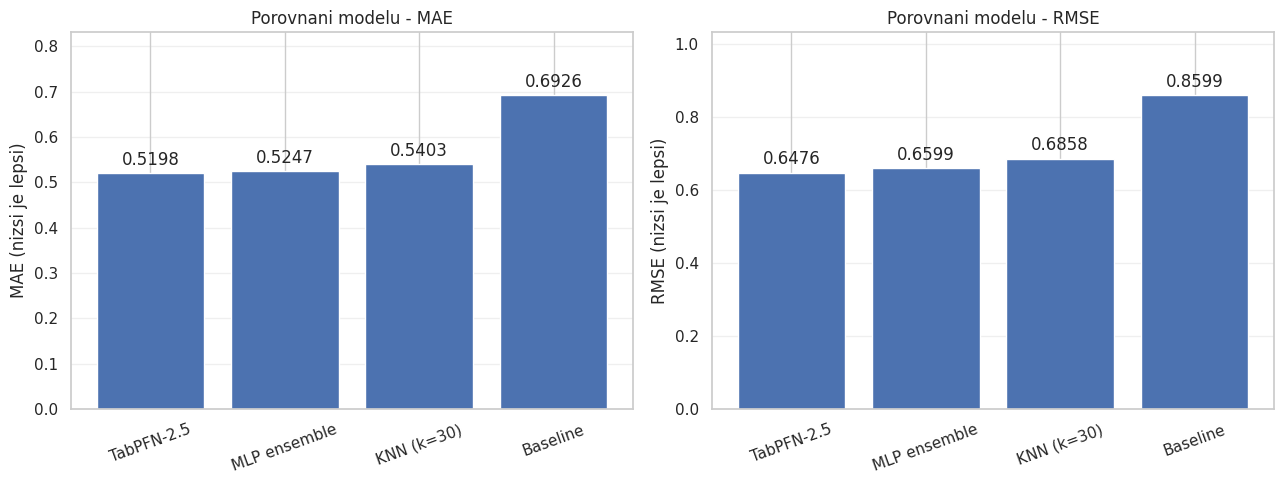

Graf ulozen: zaverecne_porovnani_modelu.png


In [38]:

import matplotlib.pyplot as plt
import numpy as np

# Vysledky z testovaci mnoziny
models = results_test["Model"]
mae = results_test["MAE"]
rmse = results_test["RMSE"]

x = np.arange(len(models))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graf MAE
bars1 = axes[0].bar(x, mae)
axes[0].set_title("Porovnani modelu - MAE")
axes[0].set_ylabel("MAE (nizsi je lepsi)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=20)
axes[0].bar_label(bars1, fmt="%.4f", padding=3)
axes[0].set_ylim(0, max(mae) * 1.2)
axes[0].grid(axis="y", alpha=0.3)

# Graf RMSE
bars2 = axes[1].bar(x, rmse)
axes[1].set_title("Porovnani modelu - RMSE")
axes[1].set_ylabel("RMSE (nizsi je lepsi)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, rotation=20)
axes[1].bar_label(bars2, fmt="%.4f", padding=3)
axes[1].set_ylim(0, max(rmse) * 1.2)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("zaverecne_porovnani_modelu.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Graf ulozen: zaverecne_porovnani_modelu.png")


## 20. Ukázka dvou vín

Konkrétní ukázka skóre preference na testovacích datech.


In [39]:

import numpy as np
from scipy.special import expit

# Vybereme dve vina z testovaci mnoziny
rng = np.random.default_rng(42)
real_quality = np.asarray(y_test).reshape(-1)

# Vybereme dvojici s rozdilnou skutecnou kvalitou
while True:
    a, b = rng.choice(len(real_quality), size=2, replace=False)
    if real_quality[a] != real_quality[b]:
        break

# Predpovedi naseho MLP ensemble
pred_a = float(y_pred_test_ensemble[a])
pred_b = float(y_pred_test_ensemble[b])

# Preference vina A pomoci sigmoid funkce
k = 2
preference_a = expit(k * (pred_a - pred_b))

print("POROVNANI DVOU VIN")
print("------------------------------")
print(f"Vino A - skutecna kvalita: {real_quality[a]}")
print(f"Vino A - predikce modelu: {pred_a:.3f}")
print()
print(f"Vino B - skutecna kvalita: {real_quality[b]}")
print(f"Vino B - predikce modelu: {pred_b:.3f}")
print()
print(f"Skore preference vina A: {preference_a:.2%}")
print(f"Skore preference vina B: {1-preference_a:.2%}")

if pred_a > pred_b:
    print("\nModel preferuje vino A.")
elif pred_b > pred_a:
    print("\nModel preferuje vino B.")
else:
    print("\nModel hodnoti obe vina stejne.")

if (pred_a > pred_b) == (real_quality[a] > real_quality[b]):
    print("Porovnani odpovida skutecnemu hodnoceni.")
else:
    print("Porovnani neodpovida skutecnemu hodnoceni.")


POROVNANI DVOU VIN
------------------------------
Vino A - skutecna kvalita: 5
Vino A - predikce modelu: 5.327

Vino B - skutecna kvalita: 6
Vino B - predikce modelu: 6.026

Skore preference vina A: 19.81%
Skore preference vina B: 80.19%

Model preferuje vino B.
Porovnani odpovida skutecnemu hodnoceni.


## 21. Přesnost porovnávání na testu

Orientace podle pořadí predikovaných kvalit; sigmoidní parametr k nemění pořadí.


In [40]:

import numpy as np
import pandas as pd
from scipy.special import expit

rng = np.random.default_rng(42)

real_quality = np.asarray(y_test).reshape(-1)
pred_quality = np.asarray(y_pred_test_ensemble).reshape(-1)

n_pairs = 1000
pair_results_test = []

for _ in range(n_pairs):
    a, b = rng.choice(len(real_quality), size=2, replace=False)

    real_a = real_quality[a]
    real_b = real_quality[b]

    # Preskocime vina se stejnou skutecnou kvalitou
    if real_a == real_b:
        continue

    pred_a = pred_quality[a]
    pred_b = pred_quality[b]

    preference_a = expit(2 * (pred_a - pred_b))

    correct = (pred_a > pred_b) == (real_a > real_b)

    pair_results_test.append({
        "Skutecna A": real_a,
        "Skutecna B": real_b,
        "Predikce A": pred_a,
        "Predikce B": pred_b,
        "Preference A": preference_a,
        "Spravne": correct
    })

pairs_test_df = pd.DataFrame(pair_results_test)

n_correct = int(pairs_test_df["Spravne"].sum())
n_evaluated = len(pairs_test_df)
accuracy_test = 100 * n_correct / n_evaluated

print("POROVNANI DVOJIC - TESTOVACI DATA")
print(f"Vygenerovano dvojic: {n_pairs}")
print(f"Hodnoceno dvojic: {n_evaluated}")
print(f"Spravne porovnani: {n_correct}")
print(f"Presnost: {accuracy_test:.2f} %")

print("\nUKAZKA PRVNICH 10 DVOJIC")
display(pairs_test_df.head(10).round(3))


POROVNANI DVOJIC - TESTOVACI DATA
Vygenerovano dvojic: 1000
Hodnoceno dvojic: 679
Spravne porovnani: 550
Presnost: 81.00 %

UKAZKA PRVNICH 10 DVOJIC


,Skutecna A,Skutecna B,Predikce A,Predikce B,Preference A,Spravne
0,5,6,5.327,6.026,0.198,True
1,7,6,6.300,5.692,0.771,True
2,5,6,5.388,7.164,0.028,True
3,4,5,4.985,5.299,0.348,True
4,6,7,6.442,5.616,0.839,False
5,6,5,6.711,4.934,0.972,True
6,4,6,5.354,5.287,0.534,False
7,5,6,5.203,5.590,0.316,True
8,6,5,5.569,5.779,0.397,False
9,5,6,5.412,5.418,0.497,True


## 22. Souhrn a export

Přehled tabulek a export CSV.


In [41]:

import pandas as pd

print("=" * 55)
print("ZAVERECNE SHRNUTI PROJEKTU - WINE QUALITY")
print("=" * 55)

print("\n1. DATASET")
print(f"Trenovaci data: {len(X_train)} vzorku")
print(f"Validacni data: {len(X_val)} vzorku")
print(f"Testovaci data: {len(X_test)} vzorku")
print(f"Pocet vstupnich priznaku: {X_train.shape[1]}")

print("\n2. POROVNANI MODELU - TESTOVACI DATA")
display(results_test.round(4))

print("\n3. LADENI LEARNING RATE")
display(results_lr.round(4))

print("\n4. POROVNANI ARCHITEKTUR")
display(results_arch.round(4))

print("\n5. STABILITA MLP - TRI NAHODNA SEMINKA")
display(results_seeds.round(4))

print("\n6. VLIV MNOZSTVI TRENOVACICH DAT")
display(results_data.round(4))

print("\n7. POROVNAVANI DVOJIC VIN")
print("Validacni presnost poradi dvojic vin (drive namerena): 81.89 %")
print(f"Testovaci presnost: {accuracy_test:.2f} %")

print("\n8. MODEL S NEJNIZSI CHYBOU NA TESTOVACICH DATECH")
best_model = results_test.iloc[0]
print(f"Model: {best_model['Model']}")
print(f"MAE: {best_model['MAE']:.4f}")
print(f"RMSE: {best_model['RMSE']:.4f}")

# Ulozeni tabulek pro zaverecnou zpravu
results_test.to_csv("vysledky_modelu.csv", index=False)
results_lr.to_csv("ladeni_learning_rate.csv", index=False)
results_arch.to_csv("porovnani_architektur.csv", index=False)
results_seeds.to_csv("stabilita_modelu.csv", index=False)
results_data.to_csv("vliv_mnozstvi_dat.csv", index=False)

print("\nTabulky byly ulozeny do CSV souboru.")
print("SHRNUTI DOKONCENO")


ZAVERECNE SHRNUTI PROJEKTU - WINE QUALITY

1. DATASET
Trenovaci data: 3724 vzorku
Validacni data: 798 vzorku
Testovaci data: 798 vzorku
Pocet vstupnich priznaku: 12

2. POROVNANI MODELU - TESTOVACI DATA


,Model,MAE,RMSE
0,TabPFN-2.5,0.5198,0.6476
1,MLP ensemble,0.5247,0.6599
2,KNN (k=30),0.5403,0.6858
3,Baseline,0.6926,0.8599



3. LADENI LEARNING RATE


,Learning rate,MAE,RMSE,Nejlepsi epocha,Celkem epoch
0,0.001,0.5580,0.7321,1000,1000
1,0.003,0.5484,0.7238,924,974
2,0.010,0.5453,0.7157,400,450



4. POROVNANI ARCHITEKTUR


...


5. STABILITA MLP - TRI NAHODNA SEMINKA


,Seed,MAE,RMSE,Nejlepsi epocha
0,42,0.5361,0.7038,296
1,123,0.5344,0.6955,451
2,2026,0.5327,0.7011,305



6. VLIV MNOZSTVI TRENOVACICH DAT


,Podil dat,Pocet vzorku,MAE,RMSE,Nejlepsi epocha
0,25 %,931,0.5528,0.7298,300
1,50 %,1862,0.5360,0.7089,290
2,75 %,2793,0.5356,0.7036,269
3,100 %,3724,0.5363,0.7039,295



7. POROVNAVANI DVOJIC VIN
Validacni presnost poradi dvojic vin (drive namerena): 81.89 %
Testovaci presnost: 81.00 %

8. MODEL S NEJNIZSI CHYBOU NA TESTOVACICH DATECH
Model: TabPFN-2.5
MAE: 0.5198
RMSE: 0.6476

Tabulky byly ulozeny do CSV souboru.
SHRNUTI DOKONCENO


## 23. Omezení experimentů a závěr

### Omezení experimentů

- **Velikost datasetu:** Experimenty byly provedeny na 5 320 záznamech vín po odstranění přesných duplicit. Výsledky proto nemusí být přenositelné na jiné datasety.
- **Nerovnoměrné zastoupení kvalit:** Většina vín má hodnocení 5 nebo 6, zatímco krajní hodnoty jsou zastoupeny výrazně méně.
- **Náhodná semínka:** Stabilita výsledků byla ověřena třemi běhy s různými náhodnými semínky (42, 123 a 2026) pro modely MLP a TabPFN-2.5. U MLP jde o odlišné náhodné inicializace vah, zatímco u předtrénovaného TabPFN změna semínka ovlivňuje jeho interní náhodné mechanismy. Výsledky byly vyhodnoceny pomocí průměru a výběrové směrodatné odchylky na stejné validační množině. Tři běhy poskytují pouze orientační odhad variability.
- **Porovnávání dvojic vín:** Dvojice byly náhodně vybírány z dostupných dat, a jednotlivá vína se proto mohla vyskytovat opakovaně. Výsledná přesnost není založena na zcela nezávislých dvojicích.
- **Sigmoidní funkce:** Výstup sigmoidní funkce představuje skóre preference odvozené z rozdílu předpovězených kvalit, nikoli skutečnou kalibrovanou pravděpodobnost, že bude jedno víno preferováno před druhým.
- **Subjektivita hodnocení:** Kvalita vín je založena na senzorickém hodnocení, které může být subjektivní.

### Závěr

Cílem projektu bylo předpovídat kvalitu vína na základě jeho fyzikálně-chemických vlastností a následně využít predikované hodnoty k porovnávání dvojic vín.

Nejlepších výsledků na testovací množině dosáhl předtrénovaný model **TabPFN-2.5 (MAE = 0,5198; RMSE = 0,6476)**. Velmi podobných výsledků dosáhlo také ensemble tří vlastních neuronových sítí MLP (MAE = 0,5247; RMSE = 0,6599).

Při porovnávání dvojic vín dosáhlo ensemble MLP na testovacích datech přesnosti **81,00 %**.

Experimenty ukázaly, že vhodné nastavení hyperparametrů, architektury neuronové sítě a kombinování více modelů mohou zlepšit kvalitu predikcí.